In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# I. Cleaning the Data

### 1. Data granularity and exclusions

The original dataset contains 2,381 student records, with one row per student.

During data inspection, I identified two records associated with an Indian faculty member and the course Life Skills (Jeevan Kaushal) 2.0. These records were excluded because the course had a distinct set of quizzes that differed from those taken by the rest of the students. Since the analysis primarily focuses on Filipino learners, excluding these two records helps maintain a consistent analytical population and improves comparability across students.

The exclusion was based on differences in course and quiz structure, rather than nationality alone.

### 2. Sample selection and filtering

| Stage                                                                  | Remaining students | Excluded | % of original dataset |
| ---------------------------------------------------------------------- | ------------------ | -------- | --------------------- |
| Original dataset                                                       | 2,381              | -        | 100.00%               |
| Remove two records associated with Life Skills (Jeevan Kaushal) 2.0    | 2,379              | 2        | 99.92%                |
| Exclude students with fewer than two completed quizzes                 | 2,086              | 293      | 87.61%                |
| Restrict to courses with 14 quizzes, excluding courses with 11 quizzes | 2,048              | 38       | 86.01%                |
| Completed all 14 quizzes (none actually removed for this stage)        | 1,859              | 189      | 78.08%                |

The final analytical dataset contains 2,048 students who meet the inclusion criteria.

### 3. Selected variables and rationale

The selected variables support the analysis of students' quiz performance, course completion, and pacing relative to their enrollment and course end dates.

| Variable                            | Purpose                                                                                                                                                                                                                                              |
| ----------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `student_id`                        | Identifies each student and serves as the student-level identifier.                                                                                                                                                                                  |
| `batch_id`                          | Groups students by batch to enable cohort-level comparisons of quiz performance and completion pacing.                                                                                                                                               |
|`total_of_quizzes_incourse`.         | Number of Quizzes in the Course |
| `is_completed_all_courses`          | Indicates whether the student completed all assigned courses, providing context for interpreting their progress.                                                                                                                                     |
| `average_quiz_score`                | Serves as the primary source of truth for overall quiz performance. Although it is similar to the mean calculated from individual quiz scores, discrepancies exist, so the dataset-provided value is retained for consistency.                       |
| `lessons_average_score_in_course`   | Captures lesson-level performance, which is treated separately from quiz performance.                                                                                                                                                                |
| `total_lessons_completed_in_course` | Measures lesson completion and provides additional context on student engagement with course materials.                                                                                                                                              |
| `batch_end_date`                    | Serves as a proxy for the expected course end date and provides a reference point for assessing completion timing.                                                                                                                                   |
| `first_course_enrollment_date`      | Establishes the starting reference date for the student's course timeline. This was preferred over `batch_start_date` because quiz attempts can occur before the batch start date, whereas the enrollment date precedes the student's quiz attempts. |
| `last_quiz_attempt_date`            | Captures the date of the student's most recent quiz attempt and serves as the endpoint for calculating observed quiz activity.                                                                                                                       |

The `total_of_quizzes_incourse` and `batch_start_date` variables were not retained in the final selection. The former was unnecessary after restricting the analysis to courses with 14 quizzes, while the latter was less suitable than the student's first course enrollment date as the starting point for the timeline.

### 4. Important analytical considerations

- Quiz performance and lesson performance are distinct measures. They should not be treated as interchangeable indicators of learning.
- Completion status and pacing are also distinct. A student may complete quizzes quickly without necessarily completing all course requirements.
- The last quiz attempt is not necessarily the course completion date. It is an observable proxy for the end of quiz activity, not definitive evidence that the student finished the course on that date.
- The 14-quiz restriction improves comparability. Students taking courses with different quiz requirements may not be directly comparable in terms of quiz completion or pacing.

These criteria establish a consistent population for the subsequent analysis of quiz-taking behavior and potential early completion risk. However, unusually fast quiz completion should be interpreted as a potential risk indicator, not proof that a student failed to learn the material.

In [2]:
student_data_df = pd.read_excel('Case Assignment - Sr Associate - Philippines - data.xlsx')
student_data_df.rename(columns={'competency_quiz_score_1': 'Competency_quiz_score_1'}, inplace=True)

# get competency quiz columns 
competency_name_lists = [f"Competency_name_{i}" for i in range(1, 15)]
competency_quiz_submit_lists = [f"Competency_quiz_submit_{i}" for i in range(1, 15)]
competency_quiz_score_lists = [f"Competency_quiz_score_{i}" for i in range(1, 15)]
competency_quizzes = competency_name_lists + competency_quiz_submit_lists + competency_quiz_score_lists

# remove the two students that have a different course
student_data_df = student_data_df[student_data_df['course_name'] != 'Life Skills (Jeevan Kaushal) 2.0'].copy()
# remove students that dont have at least two answered quizzes
student_data_df = student_data_df.dropna(subset=competency_quiz_submit_lists, thresh=2)

In [3]:
competency_quiz_time_deltas = {f'Competency_quiz_delta_{i}':[] for i in range(1, 15)}
competency_quiz_time_submits = {i:[] for i in competency_quiz_submit_lists}
competency_quiz_time_score = {i:[] for i in competency_quiz_score_lists}

competency_quizzes = {
    **competency_quiz_time_deltas,
    **competency_quiz_time_submits, 
    **competency_quiz_time_score
}

In [4]:
num_missing_quizzes = (
    student_data_df[competency_quiz_submit_lists]
    .isnull()
    .sum(axis=1)
    .value_counts()
    .sort_index()
)

num_missing_quizzes

0     1859
1       63
2       13
3       23
4       16
5       10
6       11
7       15
8       14
9        8
10      13
11      22
12      19
Name: count, dtype: int64

In [5]:
competency_quizzes = []

for _, student_row in student_data_df.iterrows():
    student_quizzes = {
        'student_id': student_row['student_id'],
        'batch_id': student_row['batch_id'],
        'total_of_quizzes_incourse': student_row['total_of_quizzes_incourse'],
        'is_completed_all_courses': student_row['is_completed_all_courses'],
        'average_quiz_score': student_row['average_quiz_score'],
        'lessons_average_score_in_course': student_row['lessons_average_score_in_course'],
        'total_lessons_completed_in_course': student_row['total_lessons_completed_in_course'],
        'batch_end_date': student_row['batch_end_date'],
        #'batch_start_date': student_row['batch_start_date'],
        'first_course_enrollment_date': student_row['first_course_enrollment_date'],
        'last_quiz_attempt_date': student_row['last_quiz_attempt_date']
    }

    previous_date = student_row['first_course_enrollment_date']
    cumulative_delta = pd.Timedelta(0)

    for i in range(1, 15):
        submit_col = f'Competency_quiz_submit_{i}'
        score_col = f'Competency_quiz_score_{i}'
        delta_col = f'Competency_quiz_delta_{i}'
        cumsum_col = f'Competency_quiz_cumsum_{i}'

        submit_date = student_row[submit_col]
        score = student_row[score_col]

        if pd.notna(submit_date):
            delta = submit_date - previous_date
            cumulative_delta += delta

            student_quizzes[submit_col] = submit_date
            student_quizzes[score_col] = score
            student_quizzes[delta_col] = delta
            student_quizzes[cumsum_col] = cumulative_delta

            previous_date = submit_date

        else:
            student_quizzes[submit_col] = pd.NaT
            student_quizzes[score_col] = None
            student_quizzes[delta_col] = pd.NaT
            student_quizzes[cumsum_col] = pd.NaT

    competency_quizzes.append(student_quizzes)

competency_quizzes_df = pd.DataFrame(competency_quizzes)
competency_quizzes_df.to_csv('cleaned_case_assignment.csv', index=False)

# II. Exploratory Data Analysis

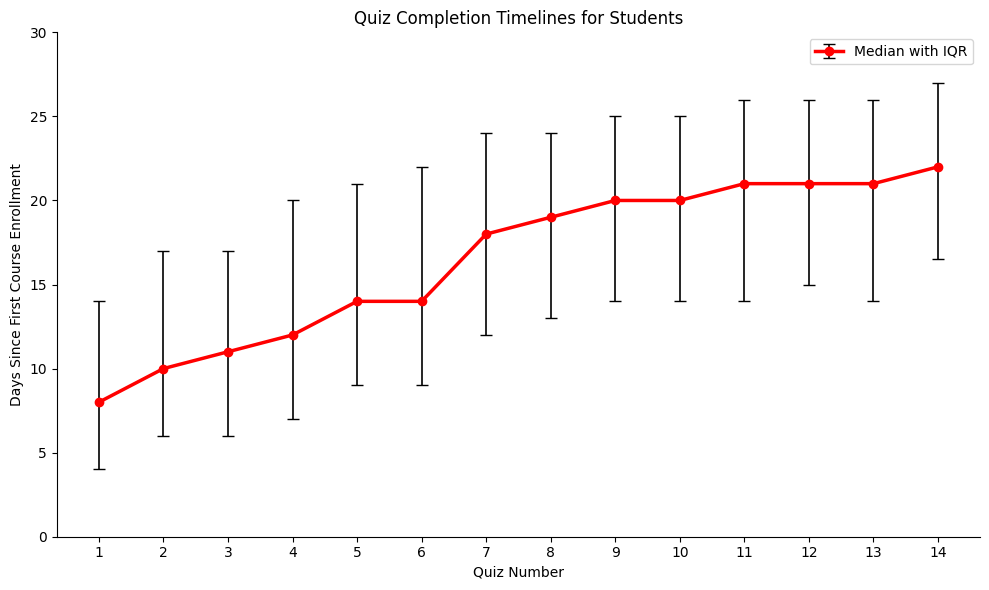

In [46]:
# Filter students who have 14 quizzes in the course.
students_14_quizzes = competency_quizzes_df[
    (competency_quizzes_df['total_of_quizzes_incourse'] == 14)
    & (competency_quizzes_df['is_completed_all_courses'] == 'Y')
]

quiz_delta_cols = list(competency_quiz_time_deltas.keys())

plt.figure(figsize=(10, 6))

all_quiz_days = []

for _, student_row in students_14_quizzes.iterrows():
    quiz_deltas = student_row[quiz_delta_cols].apply(lambda x : int(x.days))

    # Cumulative days since enrollment.
    quiz_days = quiz_deltas.cumsum()
    all_quiz_days.append(quiz_days.to_numpy(dtype=float))

# Calculate median and interquartile range for each quiz.
all_quiz_days = np.array(all_quiz_days)

median_quiz_days = np.nanmedian(all_quiz_days, axis=0)
q25 = np.nanpercentile(all_quiz_days, 25, axis=0)
q75 = np.nanpercentile(all_quiz_days, 75, axis=0)

# Asymmetric error bars: median down to Q1, median up to Q3.
yerr = np.array([
    median_quiz_days - q25,
    q75 - median_quiz_days
])

plt.errorbar(
    range(1, 15),
    median_quiz_days,
    yerr=yerr,
    color='red',
    ecolor='black',
    elinewidth=1.2,
    capsize=4,
    linewidth=2.5,
    marker='o',
    label='Median with IQR'
)

plt.xlabel('Quiz Number')
plt.ylabel('Days Since First Course Enrollment')
plt.ylim(0, 30)
plt.title('Quiz Completion Timelines for Students')
plt.xticks(range(1, 15))
#plt.grid(True, alpha=0.3)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.legend()
plt.tight_layout()
plt.show()

<Axes: >

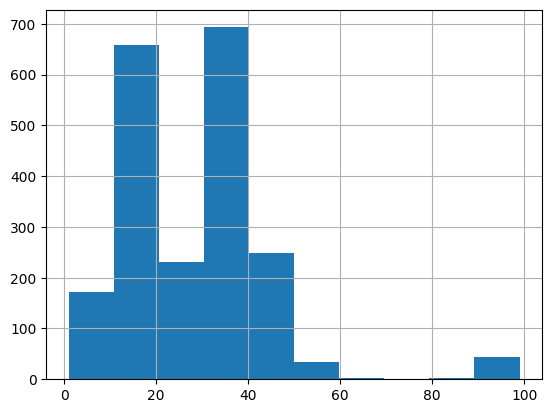

In [102]:
(competency_quizzes_df['batch_end_date'] - competency_quizzes_df['first_course_enrollment_date']).dt.days.hist()

# III. Batch Based Threshold

In [50]:
submit_cols = [
    f'Competency_quiz_submit_{i}'
    for i in range(1, 15)
]

# Keep students who completed all 14 quizzes.
finishers_df = competency_quizzes_df[
    competency_quizzes_df[submit_cols].notna().all(axis=1)
].copy()


percentiles = range(0, 20, 1)

sensitivity_results = []

for percentile in percentiles:
    threshold_col = f'p{percentile}_days'

    # Calculate the threshold within each batch.
    batch_threshold = (
        finishers_df
        .groupby('batch_id')['Competency_quiz_cumsum_14']
        .quantile(percentile / 100)
    )

    # Map each batch's threshold to its students.
    threshold = finishers_df['batch_id'].map(batch_threshold)

    flagged = finishers_df[
        finishers_df['Competency_quiz_cumsum_14'] <= threshold
    ]

    sensitivity_results.append({
        'percentile': percentile,
        'threshold_median_days': batch_threshold.median(),
        'students_flagged': flagged['student_id'].nunique(),
        'pct_students_flagged': (
            flagged['student_id'].nunique()
            / finishers_df['student_id'].nunique()
            * 100
        ),
        'flagged_median_quiz_score': flagged['average_quiz_score'].mean(),
        'other_median_quiz_score': finishers_df.loc[
            ~finishers_df.index.isin(flagged.index),
            'average_quiz_score'
        ].mean(),
        'flagged_median_lesson_score': flagged['lessons_average_score_in_course'].mean(),
        'other_median_lesson_score': finishers_df.loc[
            ~finishers_df.index.isin(flagged.index),
            'lessons_average_score_in_course'
        ].mean(),
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

In [51]:
sensitivity_df

,percentile,threshold_median_days,students_flagged,pct_students_flagged,flagged_median_quiz_score,other_median_quiz_score,flagged_median_lesson_score,other_median_lesson_score
0,0,4 days 00:00:00,89,4.787520,91.280899,90.114124,47.133548,50.431485
1,1,5 days 16:04:48,89,4.787520,91.280899,90.114124,47.133548,50.431485
2,2,7 days 16:33:36,91,4.895105,91.087912,90.122738,47.259112,50.430009
3,3,9 days 00:00:00,120,6.455083,91.150000,90.102358,47.535604,50.469340
4,4,9 days 20:09:36,137,7.369554,91.051095,90.099884,47.341908,50.514486
5,5,10 days 16:12:00,171,9.198494,90.976608,90.088270,49.426760,50.378918
6,6,11 days 11:16:48,183,9.844002,91.071038,90.071599,49.581019,50.370573
7,7,12 days 02:09:36,202,10.866057,91.138614,90.051901,49.529828,50.385568
8,8,12 days 15:21:36,219,11.780527,91.136986,90.040854,49.442114,50.406131
9,9,13 days 00:00:00,237,12.748790,91.004219,90.048089,49.470649,50.412341


# IV. Overall Treshold

In [108]:
import numpy as np
import pandas as pd
from scipy import stats

score_cols = [
    'average_quiz_score',
    'lessons_average_score_in_course',
]

percentiles = range(1, 20)

df = competency_quizzes_df.copy()
sensitivity_results = []

quiz_number = 7
for percentile in percentiles:
    threshold = df[f'Competency_quiz_cumsum_{quiz_number}'].quantile(
        percentile / 100
    )

    flagged_mask = df[f'Competency_quiz_cumsum_{quiz_number}'] < threshold
    flagged = df.loc[flagged_mask]
    other = df.loc[~flagged_mask]

    result = {
        'percentile': percentile,
        'threshold_days': threshold.days, 
        'students_flagged': flagged['student_id'].nunique(),
    }

    for col in score_cols:
        x = flagged[col].dropna()
        y = other[col].dropna()

        prefix = (
            col.replace('average_', '')
            .replace('_average_score', '')
            .replace('_in_course', '')
        )

        # Welch's t-test
        if len(x) >= 2 and len(y) >= 2:
            result[f'{prefix}_p'] = stats.ttest_ind(
                x, y, equal_var=False
            ).pvalue

            # Cohen's d using pooled standard deviation
            pooled_sd = np.sqrt(
                (
                    (len(x) - 1) * x.var(ddof=1)
                    + (len(y) - 1) * y.var(ddof=1)
                )
                / (len(x) + len(y) - 2)
            )

            result[f'{prefix}_cohens_d'] = (
                (x.mean() - y.mean()) / pooled_sd
                if pooled_sd > 0 else np.nan
            )
        else:
            result[f'{prefix}_p'] = np.nan
            result[f'{prefix}_cohens_d'] = np.nan

    sensitivity_results.append(result)

sensitivity_df = pd.DataFrame(sensitivity_results)
sensitivity_df.round(3)

,percentile,threshold_days,students_flagged,quiz_score_p,quiz_score_cohens_d,lessons_score_p,lessons_score_cohens_d
0,1,0,0,NaN,NaN,NaN,NaN
1,2,1,28,0.014,0.256,0.027,-0.597
2,3,2,50,0.825,0.029,0.012,-0.503
3,4,3,72,0.876,-0.017,0.010,-0.377
4,5,4,96,0.516,0.057,0.034,-0.270
5,6,5,117,0.184,0.101,0.016,-0.251
6,7,5,117,0.184,0.101,0.016,-0.251
7,8,6,144,0.164,0.094,0.002,-0.273
8,9,7,174,0.201,0.082,0.000,-0.326
9,10,7,174,0.201,0.082,0.000,-0.326


In [107]:
df = competency_quizzes_df.copy()

threshold = df['Competency_quiz_cumsum_7'].quantile(0.04)

flagged = df[
    df['Competency_quiz_cumsum_7'] < threshold
]

other = df[
    df['Competency_quiz_cumsum_7'] >= threshold
]

score_col = 'lessons_average_score_in_course'
# score_col = 'average_quiz_score'

x = flagged[score_col].dropna()
y = other[score_col].dropna()

# Descriptive statistics
print("Flagged students")
print(f"n: {len(x)}")
print(f"Mean: {x.mean():.2f}")
print(f"Median: {x.median():.2f}")
print(f"SD: {x.std():.2f}")

print("\nOther students")
print(f"n: {len(y)}")
print(f"Mean: {y.mean():.2f}")
print(f"Median: {y.median():.2f}")
print(f"SD: {y.std():.2f}")

# Cohen's d
pooled_sd = np.sqrt(
    (
        (len(x) - 1) * x.var(ddof=1)
        + (len(y) - 1) * y.var(ddof=1)
    ) / (len(x) + len(y) - 2)
)

cohens_d = (x.mean() - y.mean()) / pooled_sd

# Welch's t-test and 95% confidence interval
test = stats.ttest_ind(x, y, equal_var=False)

se = np.sqrt(
    x.var(ddof=1) / len(x)
    + y.var(ddof=1) / len(y)
)

df_welch = (
    x.var(ddof=1) / len(x)
    + y.var(ddof=1) / len(y)
) ** 2 / (
    (x.var(ddof=1) / len(x)) ** 2 / (len(x) - 1)
    + (y.var(ddof=1) / len(y)) ** 2 / (len(y) - 1)
)

critical = stats.t.ppf(0.975, df_welch)
difference = x.mean() - y.mean()

print(f"\nMean difference: {difference:.2f}")
print(f"Cohen's d: {cohens_d:.3f}")
print(
    "95% CI for mean difference: "
    f"[{difference - critical * se:.2f}, "
    f"{difference + critical * se:.2f}]"
)
print(f"Welch's t-test p-value: {test.pvalue:.5f}")

Flagged students
n: 49
Mean: 43.66
Median: 43.54
SD: 15.27

Other students
n: 1791
Mean: 49.85
Median: 49.69
SD: 15.51

Mean difference: -6.19
Cohen's d: -0.399
95% CI for mean difference: [-10.63, -1.75]
Welch's t-test p-value: 0.00725
